# 12 -- STEM contrast transfer and the quantum probe, validated against abTEM

A STEM image starts with the **probe**: an aperture $A(k)$ in the back focal plane of the probe-forming lens, multiplied by the lens aberration phase $e^{-i\chi(k)}$, then brought to focus on the specimen,

$$
\psi_{\text{probe}}(\mathbf r)=\mathcal F^{-1}\!\left[A(k)\,e^{-i\chi(k)}\right],\qquad
\chi(k)=\pi\lambda C_1k^2+\tfrac{\pi}{2}\lambda^3C_3k^4+\tfrac{\pi}{3}\lambda^5C_5k^6 .
$$

QuScope builds this as a **quantum circuit**: the k-space probe is amplitude-encoded on $2\log_2 N$ qubits by `QuantumWaveFunction`, and the 2D quantum Fourier transform takes it to real space. This notebook checks three things against abTEM at 200 kV:

1. the aberration function and its contrast transfer function (`CTFCalculator` vs abTEM),
2. the probe produced by the quantum circuit (real-space intensity),
3. the STEM transfer function for incoherent (ADF) imaging, $|\mathcal F[\,|\psi_{\text{probe}}|^2\,]|$.

**Requires** QuScope >= 0.2.1 and abTEM >= 1.0 (`pip install git+https://github.com/QuScope/QuScope.git abtem`).

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import abtem
from abtem.transfer import CTF

from quscope.quantum_ctem.ctf_calculator import CTFCalculator, CTFParameters
from quscope.quantum_ctem.quantum_ctem_circuit import relativistic_wavelength
from quscope.quantum_ctem.quantum_wave_function import QuantumWaveFunction

abtem.config.set({"local_diagnostics.progress_bar": False})

VOLTAGE = 200e3
LAM = relativistic_wavelength(VOLTAGE)      # Angstrom
print(f"wavelength at {VOLTAGE/1e3:.0f} kV: {LAM:.5f} A")

# (Cs [mm], defocus C1 [A], convergence semi-angle [mrad]); C1 < 0 is under-focus
CASES = {
    "aberration-free, 22 mrad":      (0.0, 0.0, 22.0),
    "Cs-corrected, C1 = -100 A":     (0.0, -100.0, 22.0),
    "Cs = 1.3 mm, focus 0, 10 mrad": (1.3, 0.0, 10.0),
    "Cs = 1.3 mm, Scherzer, 10 mrad": (1.3, -1.2 * np.sqrt(1.3e7 * LAM), 10.0),
}
COLORS = ["tab:blue", "tab:purple", "tab:orange", "tab:green"]

wavelength at 200 kV: 0.02508 A


## 1. Aberration function and contrast transfer function

`CTFCalculator` evaluates $\chi(k)$ and $\mathrm{CTF}=\sin\chi$. abTEM's `CTF.profiles()` returns the same function with the opposite overall sign (its transfer function is $-\sin\chi$ inside the aperture), so the comparison below plots $-$abTEM against QuScope.

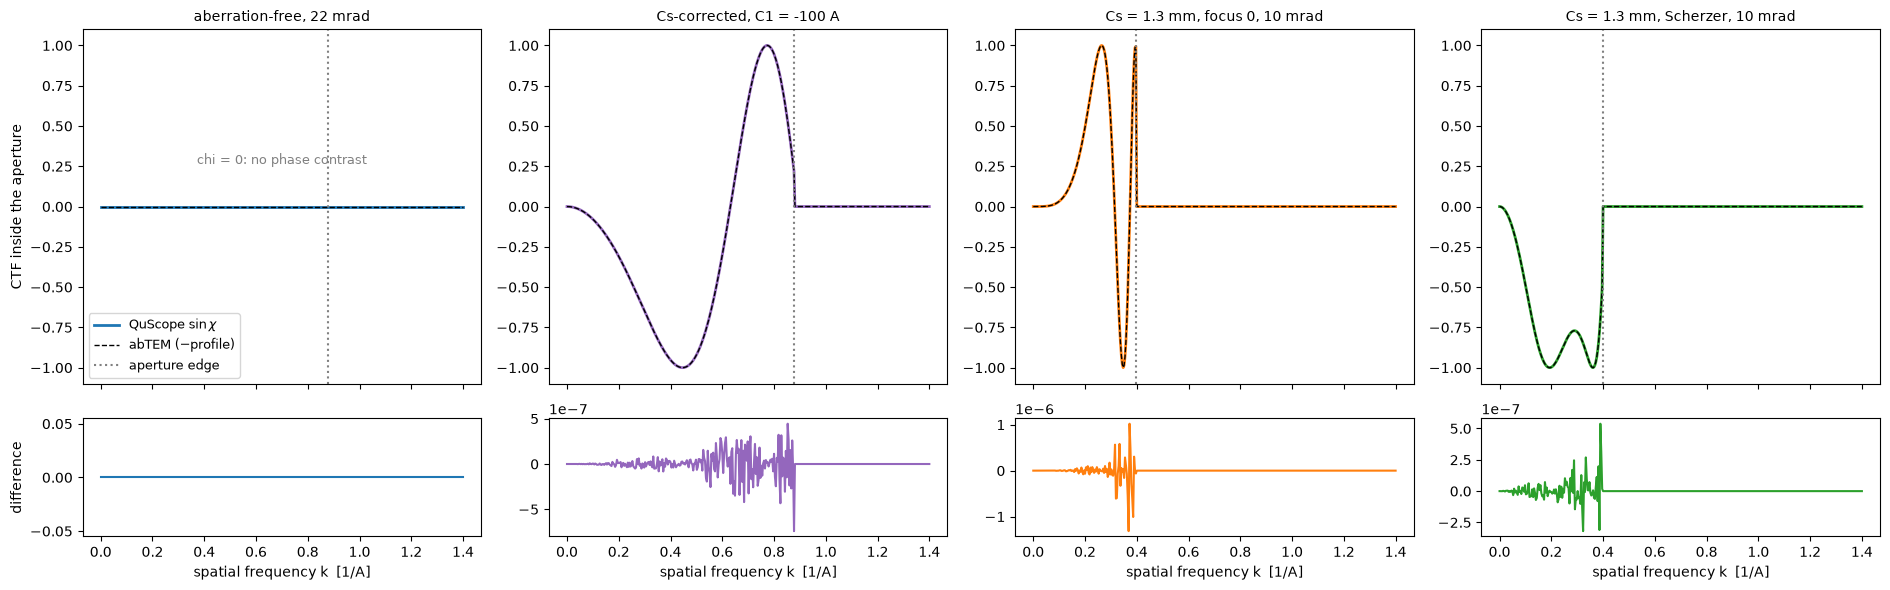

aberration-free, 22 mrad           C1 =      0.0 A   max |QuScope - abTEM| = 0.0e+00
Cs-corrected, C1 = -100 A          C1 =   -100.0 A   max |QuScope - abTEM| = 7.4e-07
Cs = 1.3 mm, focus 0, 10 mrad      C1 =      0.0 A   max |QuScope - abTEM| = 1.3e-06
Cs = 1.3 mm, Scherzer, 10 mrad     C1 =   -685.2 A   max |QuScope - abTEM| = 5.4e-07


In [2]:
k = np.linspace(0, 1.4, 400)                 # 1/A
alpha_mrad = k * LAM * 1e3

fig, axes = plt.subplots(2, 4, figsize=(19, 6), sharex="col",
                         gridspec_kw={"height_ratios": [3, 1]})
rows = []
for col, (name, (cs, df, a)) in enumerate(CASES.items()):
    calc = CTFCalculator(CTFParameters(voltage=VOLTAGE, defocus=df, cs=cs, aperture=a))
    ctf_q = np.sin(calc.chi(k)) * (alpha_mrad <= a)

    ab = CTF(energy=VOLTAGE, C10=df, C30=cs * 1e7, semiangle_cutoff=a)
    prof = ab.profiles(gpts=len(k), max_angle=alpha_mrad[-1])
    ctf_a = -prof.array[0].astype(float)     # abTEM's sign convention

    err = np.abs(ctf_q - ctf_a).max()
    rows.append((name, df, err))
    axes[0, col].plot(k, ctf_q, color=COLORS[col], lw=2, label="QuScope $\\sin\\chi$")
    axes[0, col].plot(k, ctf_a, "k--", lw=1, label="abTEM ($-$profile)")
    axes[0, col].axvline(a * 1e-3 / LAM, color="grey", ls=":", label="aperture edge")
    axes[0, col].set_title(name, fontsize=10)
    axes[0, col].set_ylim(-1.1, 1.1)
    axes[1, col].plot(k, ctf_q - ctf_a, color=COLORS[col])
    axes[1, col].set_xlabel("spatial frequency k  [1/A]")
axes[0, 0].set_ylabel("CTF inside the aperture")
axes[0, 0].text(0.5, 0.62, "chi = 0: no phase contrast", transform=axes[0, 0].transAxes, ha="center", fontsize=9, color="grey")
axes[1, 0].set_ylabel("difference")
axes[0, 0].legend(loc="lower left", fontsize=9)
plt.tight_layout(); plt.show()

for name, df, err in rows:
    print(f"{name:34s} C1 = {df:8.1f} A   max |QuScope - abTEM| = {err:.1e}")
assert all(err < 1e-5 for _, _, err in rows)

The two implementations agree to float32 precision. (QuScope's `calculate_scherzer_defocus()` uses the $1.2\sqrt{C_s\lambda}$ rule, abTEM's `scherzer_defocus` uses $\sqrt{1.5\,C_s\lambda}$; both are common conventions, so the Scherzer case above takes QuScope's value for both codes.)

## 2. The probe from a quantum circuit

Steps for each case:

1. build $\Psi(k)=A(k)e^{-i\chi(k)}$ on a $64\times64$ k-space grid (12 qubits, 0.2 A real-space pixels over a 12.8 A field),
2. amplitude-encode it with `QuantumWaveFunction.prepare_arbitrary_wave`,
3. append `create_2d_qft_circuit()`. In Qiskit's convention the QFT is the unitary *inverse* DFT, which is exactly the k-space to real-space step,
4. read out the statevector.

abTEM's default aperture has a soft edge; `soft=False` selects the hard edge used here.

In [3]:
N, EXTENT = 64, 12.8                          # grid points, field of view [A]
PX = EXTENT / N
f = np.fft.fftfreq(N, d=PX)
KX, KY = np.meshgrid(f, f, indexing="ij")
K = np.hypot(KX, KY)

def quantum_probe(cs, df, a):
    calc = CTFCalculator(CTFParameters(voltage=VOLTAGE, defocus=df, cs=cs, aperture=a))
    psi_k = (K <= a * 1e-3 / LAM) * np.exp(-1j * calc.chi(K))
    qwf = QuantumWaveFunction(int(np.log2(N)), int(np.log2(N)))
    qc = qwf.prepare_arbitrary_wave(psi_k)          # amplitude encoding
    qc.compose(qwf.create_2d_qft_circuit(), inplace=True)
    return qwf.extract_wave(qc), qc

def abtem_probe(cs, df, a):
    p = abtem.Probe(energy=VOLTAGE, semiangle_cutoff=a, C10=df, C30=cs * 1e7,
                    soft=False, gpts=N, extent=EXTENT)
    return p.build((0, 0)).compute().array

def centred_intensity(psi):
    # both probes are built at the origin (pixel 0, 0); move it to the middle for display
    I = np.abs(psi) ** 2
    return np.roll(I / I.sum(), (N // 2, N // 2), (0, 1))

probes = {}
for name, (cs, df, a) in CASES.items():
    psi_q, qc = quantum_probe(cs, df, a)
    probes[name] = (centred_intensity(psi_q), centred_intensity(abtem_probe(cs, df, a)))

print(f"circuit: {qc.num_qubits} qubits, operations {dict(qc.count_ops())}, "
      f"depth after decomposition {qc.decompose(reps=2).depth()}")

tasks:   0%|          | 0/2 [00:00<?, ?it/s]

tasks:   0%|          | 0/2 [00:00<?, ?it/s]

tasks:   0%|          | 0/2 [00:00<?, ?it/s]

tasks:   0%|          | 0/2 [00:00<?, ?it/s]

circuit: 12 qubits, operations {'QFT': 2, 'initialize': 1}, depth after decomposition 44


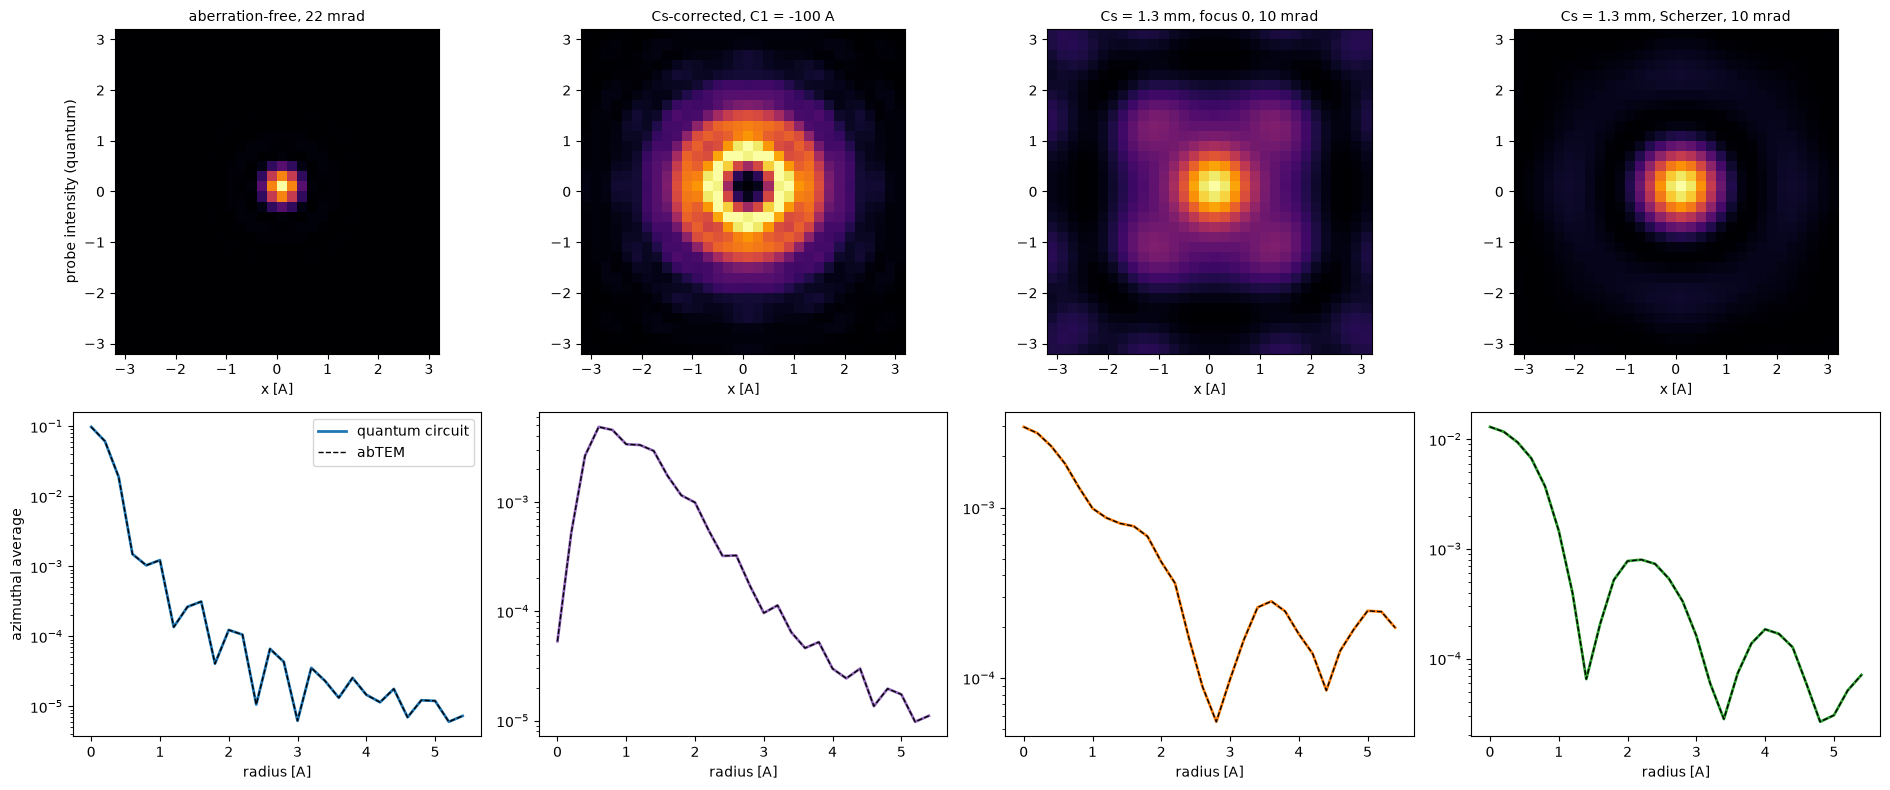

aberration-free, 22 mrad           correlation = 1.000000000000   max |diff| / peak = 1.4e-07
Cs-corrected, C1 = -100 A          correlation = 1.000000000000   max |diff| / peak = 3.9e-07
Cs = 1.3 mm, focus 0, 10 mrad      correlation = 1.000000000000   max |diff| / peak = 3.9e-07
Cs = 1.3 mm, Scherzer, 10 mrad     correlation = 1.000000000000   max |diff| / peak = 1.4e-07


In [4]:
r_axis = np.hypot(*np.meshgrid(np.arange(N) - N // 2, np.arange(N) - N // 2, indexing="ij")) * PX
rbin = np.round(r_axis / PX).astype(int)

def radial(I):
    return np.bincount(rbin.ravel(), I.ravel()) / np.bincount(rbin.ravel())

fig, axes = plt.subplots(2, 4, figsize=(19, 8))
stats = []
c = N // 2
for col, (name, (Iq, Ia)) in enumerate(probes.items()):
    sl = (slice(c - 16, c + 16), slice(c - 16, c + 16))
    ext = [-16 * PX, 16 * PX, -16 * PX, 16 * PX]
    im = axes[0, col].imshow(Iq[sl].T, origin="lower", extent=ext, cmap="inferno")
    axes[0, col].set_title(name, fontsize=10)
    axes[0, col].set_xlabel("x [A]")
    rq, ra = radial(Iq), radial(Ia)
    rr = np.arange(len(rq)) * PX
    axes[1, col].semilogy(rr[:28], rq[:28], color=COLORS[col], lw=2, label="quantum circuit")
    axes[1, col].semilogy(rr[:28], ra[:28], "k--", lw=1, label="abTEM")
    axes[1, col].set_xlabel("radius [A]")
    corr = np.corrcoef(Iq.ravel(), Ia.ravel())[0, 1]
    dmax = np.abs(Iq - Ia).max() / Ia.max()
    stats.append((name, corr, dmax))
axes[0, 0].set_ylabel("probe intensity (quantum)")
axes[1, 0].set_ylabel("azimuthal average")
axes[1, 0].legend()
plt.tight_layout(); plt.show()

for name, corr, dmax in stats:
    print(f"{name:34s} correlation = {corr:.12f}   max |diff| / peak = {dmax:.1e}")
assert all(c > 0.999999 for _, c, _ in stats)

## 3. STEM transfer function for incoherent imaging

For an annular dark-field detector the image is the specimen's scattering power convolved with the probe *intensity*, so the transfer function is $|\mathcal F[\,|\psi_{\text{probe}}|^2\,](q)|$, which cuts off at $q=2\alpha/\lambda$. The aberrations determine how fast it falls and whether it has zeros.

aberration-free, 22 mrad           max |OTF difference| = 3.3e-08
Cs-corrected, C1 = -100 A          max |OTF difference| = 5.3e-08
Cs = 1.3 mm, focus 0, 10 mrad      max |OTF difference| = 1.2e-07
Cs = 1.3 mm, Scherzer, 10 mrad     max |OTF difference| = 6.6e-08


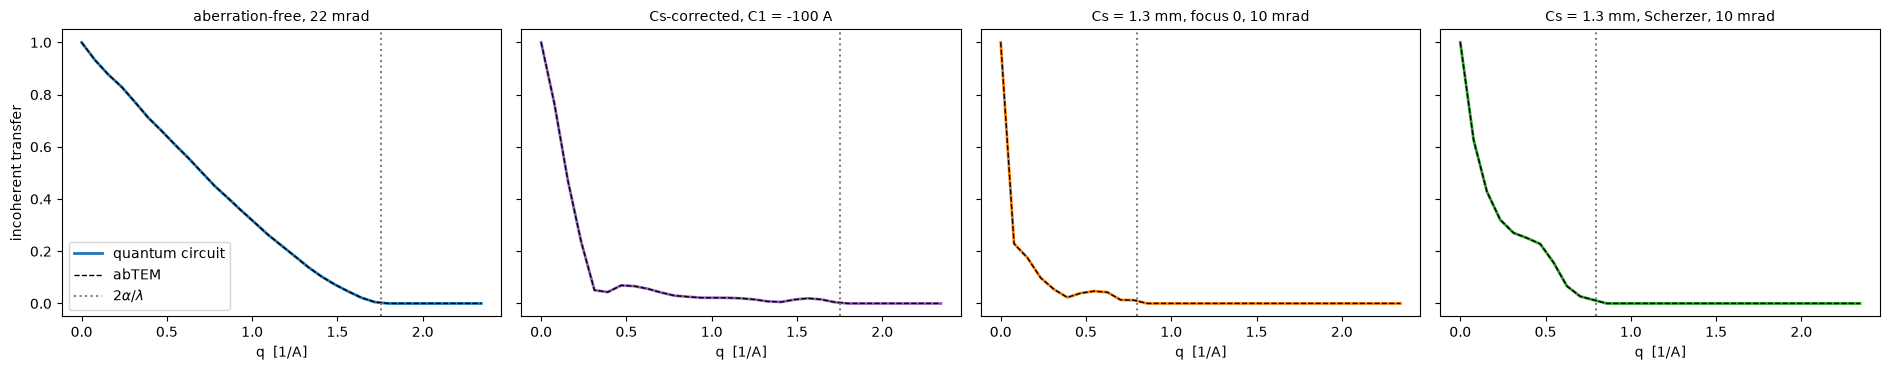

In [5]:
def otf_radial(I):
    O = np.abs(np.fft.fftshift(np.fft.fft2(np.fft.ifftshift(I))))
    O = O / O.max()
    fq = np.fft.fftshift(np.fft.fftfreq(N, d=PX))
    q = np.hypot(*np.meshgrid(fq, fq, indexing="ij"))
    qb = np.round(q / (1 / EXTENT)).astype(int)
    prof = np.bincount(qb.ravel(), O.ravel()) / np.bincount(qb.ravel())
    return np.arange(len(prof)) / EXTENT, prof

fig, axes = plt.subplots(1, 4, figsize=(19, 3.8), sharey=True)
for col, (name, (Iq, Ia)) in enumerate(probes.items()):
    qq, oq = otf_radial(Iq); _, oa = otf_radial(Ia)
    a = CASES[name][2]
    n = int(np.searchsorted(qq, 2.4))
    axes[col].plot(qq[:n], oq[:n], color=COLORS[col], lw=2, label="quantum circuit")
    axes[col].plot(qq[:n], oa[:n], "k--", lw=1, label="abTEM")
    axes[col].axvline(2 * a * 1e-3 / LAM, color="grey", ls=":", label=r"$2\alpha/\lambda$")
    axes[col].set_title(name, fontsize=10); axes[col].set_xlabel("q  [1/A]")
    print(f"{name:34s} max |OTF difference| = {np.abs(oq - oa).max():.1e}")
axes[0].set_ylabel("incoherent transfer"); axes[0].legend()
plt.tight_layout(); plt.show()

## Summary

* `CTFCalculator` and abTEM give the same aberration function (differences at the float32 level).
* The probe made by amplitude encoding plus the 2D QFT circuit equals abTEM's probe to about $10^{-7}$ of its peak.
* The quantum probe therefore carries the correct incoherent (ADF) transfer function, which sets the resolution of the STEM images in notebook 13.

The `QuantumWaveFunction` state preparation here uses `initialize`, which scales as $O(4^n)$ in classical simulation; the quantum Fourier transform itself needs only $O(n^2)$ gates on a fault-tolerant device.